# Python PDA

### Load libraries and set the dataset example 

In [1]:
# Libraries for data 
import pandas as pd
import numpy as np

# Libraries for plotting
import matplotlib.pyplot as plt

# Libraries for preprocessing and modeling 
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

df = pd.DataFrame(np.array([[7,6.5,9.2, 8.6,8], [7.5,9.4,7.3,7,7], [7.6,9.2,8,8,7.5], 
                            [5,6.5,6.5,7,9], [6,6,7.8,8.9,7.3], [7.8,9.6,7.7,8,6.6], 
                            [6.3,6.4,8.2,9,7.2], [7.9,9.7,7.5,8,6], [6,6,6.5,5.5,8.7], 
                            [6.8,7.2,8.7,9,7]]), 
                            index = ["Lucia","Pedro","Ines","Luis","Andres",
                                     "Ana","Carlos","Jose","Sonia","María"], 
                            columns = ["Matematicas", "Ciencias","Español","Historia","EdFisica"]
                            )

df


,Matematicas,Ciencias,Español,Historia,EdFisica
Lucia,7.0,6.5,9.2,8.6,8.0
Pedro,7.5,9.4,7.3,7.0,7.0
Ines,7.6,9.2,8.0,8.0,7.5
Luis,5.0,6.5,6.5,7.0,9.0
Andres,6.0,6.0,7.8,8.9,7.3
Ana,7.8,9.6,7.7,8.0,6.6
Carlos,6.3,6.4,8.2,9.0,7.2
Jose,7.9,9.7,7.5,8.0,6.0
Sonia,6.0,6.0,6.5,5.5,8.7
María,6.8,7.2,8.7,9.0,7.0


In [2]:
index = df.index
rows = len(index)
rows

10

### Standardize the data process

In [3]:
# Standardize the data process

df_standarized = StandardScaler().fit_transform(df)
df_standarized


array([[ 0.23263076, -0.7529862 ,  1.78848525,  0.65792263,  0.65465367],
       [ 0.78651352,  1.14584856, -0.53899555, -0.84590053, -0.49386154],
       [ 0.89729007,  1.01489444,  0.31849737,  0.09398895,  0.08039606],
       [-1.98290027, -0.7529862 , -1.51898747, -0.84590053,  1.80316888],
       [-0.87513476, -1.0803715 ,  0.07349939,  0.93988948, -0.14930698],
       [ 1.11884317,  1.27680268, -0.0489996 ,  0.09398895, -0.95326763],
       [-0.5428051 , -0.81846326,  0.56349535,  1.03387842, -0.2641585 ],
       [ 1.22961972,  1.34227974, -0.29399757,  0.09398895, -1.64237675],
       [-0.87513476, -1.0803715 , -1.51898747, -2.25573474,  1.45861432],
       [ 0.01107766, -0.29464677,  1.1759903 ,  1.03387842, -0.49386154]])

In [6]:
# Calculate the correlations matrix for the transformation matrix
A = (1 / rows) * np.dot(df_standarized.T, df_standarized)
A

array([[ 1.        ,  0.85407878,  0.38457424,  0.20719425, -0.78334621],
       [ 0.85407878,  1.        , -0.02005218, -0.02153942, -0.68094868],
       [ 0.38457424, -0.02005218,  1.        ,  0.82091619, -0.37030122],
       [ 0.20719425, -0.02153942,  0.82091619,  1.        , -0.51275175],
       [-0.78334621, -0.68094868, -0.37030122, -0.51275175,  1.        ]])

In [9]:
from numpy import linalg as la

### Model training PCA

In [10]:
# Model training PCA
pca_pipe = make_pipeline(StandardScaler(), PCA())
pca_pipe.fit(df)

# Extract the trained model
model_pca = pca_pipe.named_steps['pca']

print('Eigenvalues: ')
results = la.eigvals(A)
print(results)

Eigenvalues: 
[2.89165796+0.j 1.62681165+0.j 0.34790762+0.j 0.00917499+0.j
 0.12444778+0.j]


In [12]:
print('Variance Explained: ')
print(model_pca.explained_variance_)

Variance Explained: 
[3.21295329 1.80756849 0.38656403 0.13827531 0.01019443]


### Compute the eigenvetor

In [13]:
# Compute the eigenvectors
print('Eigenvector by row:')
pd.DataFrame(data = model_pca.components_, 
             columns = df.columns,
             index = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5'])

Eigenvector by row:


,Matematicas,Ciencias,Español,Historia,EdFisica
PC1,-0.525566,-0.422668,-0.361602,-0.355195,0.536854
PC2,-0.274989,-0.511731,0.559163,0.584408,0.091191
PC3,0.436194,0.042432,0.563321,-0.387617,0.583401
PC4,-0.261002,0.669419,-0.075528,0.454292,0.521221
PC5,0.624319,-0.331000,-0.483266,0.419136,0.302397


In [14]:
# Components projections 

projections = np.dot(model_pca.components_, df_standarized.T)
projections = pd.DataFrame(projections, index = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5'])
projections = projections.transpose().set_index(df.index)
projections

,PC1,PC2,PC3,PC4,PC5
Lucia,-0.332957,1.765604,1.203917,-0.059754,0.003885
Pedro,-0.667448,-1.643422,0.127831,-0.039216,-0.131652
Ines,-1.005942,-0.525747,0.624344,0.505742,0.134052
Luis,3.178176,-0.248678,-0.372700,0.683767,-0.063923
Andres,0.476002,1.370275,-0.837589,-0.151198,0.124512
Ana,-1.655122,-1.020449,-0.077963,0.112232,0.050702
Carlos,-0.081586,1.463303,-0.508927,-0.116784,0.013165
Jose,-2.022376,-1.284252,-0.566904,-0.213523,0.008203
Sonia,3.050138,-1.241108,0.442071,-0.644585,0.040936
María,-0.938885,1.364476,-0.034079,-0.076682,-0.179878


### Observations map

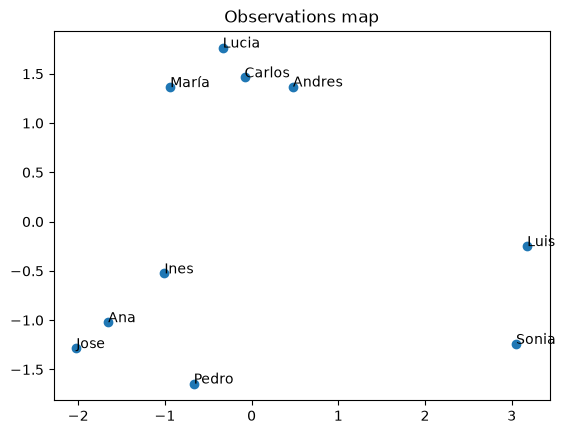

In [ ]:
x = projections.iloc[:,0]
y = projections.iloc[:,1]
z = df.index

x = x.to_numpy()
y = y.to_numpy()
z = z   

fig, ax = plt.subplots()
ax.set_title('Observations map')
ax.scatter(x, y)

for i, txt in enumerate(z):
    ax.annotate(txt, (x[i], y[i]))

In [18]:
components_2 = pd.DataFrame( data = model_pca.components_, 
                            columns = df.columns,
                            index = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5'])
components_2 = components_2.iloc[0:2, :]
components_2 = components_2.T
components_2

,PC1,PC2
Matematicas,-0.525566,-0.274989
Ciencias,-0.422668,-0.511731
Español,-0.361602,0.559163
Historia,-0.355195,0.584408
EdFisica,0.536854,0.091191


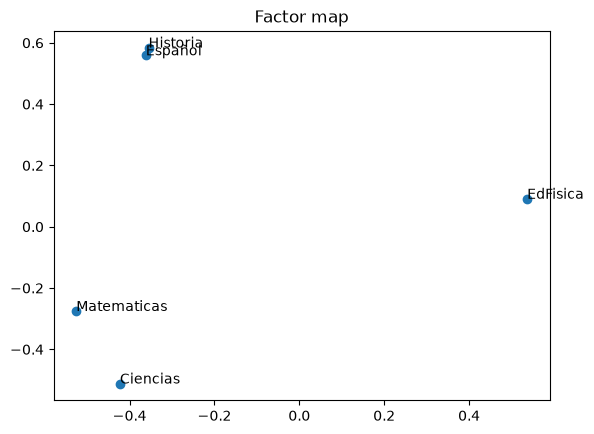

In [20]:
x = components_2.iloc[:, 0]
y = components_2.iloc[:, 1]
z = components_2.index

x = x.to_numpy()
y = y.to_numpy()

fig, ax = plt.subplots()
ax.set_title('Factor map')
ax.scatter(x, y)

for i, txt in enumerate(z):
    ax.annotate(txt, (x[i],y[i]))

In [21]:
# Process to recalculate the original matrix

original_matrix = np.dot(model_pca.components_.T, projections.T)
original_matrix = original_matrix.T
original_matrix

array([[ 0.23263076, -0.7529862 ,  1.78848525,  0.65792263,  0.65465367],
       [ 0.78651352,  1.14584856, -0.53899555, -0.84590053, -0.49386154],
       [ 0.89729007,  1.01489444,  0.31849737,  0.09398895,  0.08039606],
       [-1.98290027, -0.7529862 , -1.51898747, -0.84590053,  1.80316888],
       [-0.87513476, -1.0803715 ,  0.07349939,  0.93988948, -0.14930698],
       [ 1.11884317,  1.27680268, -0.0489996 ,  0.09398895, -0.95326763],
       [-0.5428051 , -0.81846326,  0.56349535,  1.03387842, -0.2641585 ],
       [ 1.22961972,  1.34227974, -0.29399757,  0.09398895, -1.64237675],
       [-0.87513476, -1.0803715 , -1.51898747, -2.25573474,  1.45861432],
       [ 0.01107766, -0.29464677,  1.1759903 ,  1.03387842, -0.49386154]])